### Полный пайплайн v1: STAGE → MART → Isolation Forest (baseline без нормировки на роль)

Первая production-версия пайплайна. В lakehouse еще нет stage и mart таблиц. Реализованы дедупликация RAW, фильтр полноты состава, внутриматчевой z-score, эталон по герою с fallback на позицию и исправленная формула непотраченного золота. Признаки доминирования подаются в модель **в сыром виде** — это baseline для последующего измерения эффекта нормировки.

**STAGE — объёмы и качество:**
* **1 176 570 строк / 117 657 матчей / 726 134 аккаунта / 127 героев.** Все проверки пройдены: `mean(z_dmg) = 0.0`, `std = 0.9487`, `share_top1 = 0.1` (ровно 1 из 10), пропусков в `z_dmg`, `exc_dmg`, `account_id` нет.
* Ключ `(match_id, player_slot)` уникален: все 1 176 570 ключей встречаются один раз. Дедупликация через `ROW_NUMBER` работает.
* Полнота составов идеальна: **все 117 657 матчей имеют ровно 10 строк и 5 игроков Radiant**. Фильтр `named_players = 10 AND named_radiant = 5` отработал корректно.
* **Все 127 героев прошли порог ≥100 игр** (`share_reliable_ref = 1.0`), список героев с ненадёжным эталоном пуст. Fallback на `role_ref` не потребовался ни разу.
* Исправлена семантика золота: `LEAST(gold / (gpm × duration_min), 1.0)` вместо ошибочного `1 − gold_spent / gold`. Значения теперь в диапазоне [0, 1].

**MART — профили:**
* **104 748 профилей**, среднее число матчей 3.63, `mean_exc_dmg = 0.013148` (признак центрирован).
* **855 кандидатов** по правилу `avg_exc_dmg > 1.5 AND q25_exc_dmg > 0.3`. Аккаунтов без поражений — 11 095 (10.6%), у них `avg_exc_dmg_loss` заполняется нулём с флагом `has_losses = 0`.
* Калибровка порогов: >0.5 → 5 995; >0.8 → 4 614; >1.0 → 3 242; **>1.5 → 855**; >2.0 → 152.
* Роли среди кандидатов: carry 630 (73.7%), mid_offlane 219 (25.6%), support 6 (0.7%). WR кандидатов 0.79–0.89 против 0.498 у остальных.
* Распределение по числу матчей: 3 матча — 64 969 аккаунтов / 610 кандидатов; 4 — 24 649 / 149; 5 — 9 405 / 68; 10 — 97 / 0. Средний `q25_exc_dmg` в массе отрицательный (−0.35…−0.75), что подтверждает работу фильтра устойчивости.

**ML — результаты и обнаруженная проблема:**
* Матрица признаков **(104 449, 15)**. Потеряно 299 строк из-за `handleInvalid="skip"` в VectorAssembler — тихая потеря данных, требует исправления.
* Распределение скора: медиана 0.4369, p90 0.5067, p99 0.6023, p99.9 0.6634, диапазон 0.3675–0.7044.
* Пересечение топ-500 модели и правила — **303 (60.6%)**. Методы дают существенно разные ранжирования, что оправдывает использование обоих.
* Профиль кандидатов vs остальных: `exc_dmg` 1.78 против 0.00, `exc_den` 0.69 против −0.01, WR 0.827 против 0.498, скор 0.623 против 0.445.
* **Обнаружена утечка роли:** в топ-500 по ML-скору **432 керри (86.4%)**, 65 mid/offlane (13.0%), 3 саппорта (0.6%). При этом среди `strong_candidate` керри только 73.7%. Модель **усиливает ролевое смещение на +12.7 п.п.**
* Причина: признаки `share_top1_dmg`, `share_top2_dmg`, `avg_team_dmg_share` подаются без нормировки. Керри по природе позиции чаще бывает топ-1 по урону, и Isolation Forest принимает ролевую норму за аномалию.
* Версия помечена как `v1_no_rank` / `iso_v1_no_rank`. Требуется нормировка доминирования на `farm_role` — реализовано в следующей ячейке.

In [2]:
from lakehouse_spark import SparkSessionContext
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, RobustScaler
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

with SparkSessionContext('smurf-full-pipeline') as spark:

    # ==========================================================
    # STAGE: контекст игрока внутри матча
    # ==========================================================
    player_context = spark.sql("""
        WITH matches_dedup AS (
            SELECT match_id, start_time, duration, game_mode, lobby_type, cluster, radiant_win
            FROM (
                SELECT
                    match_id, start_time, duration, game_mode, lobby_type, cluster, radiant_win,
                    ROW_NUMBER() OVER (PARTITION BY match_id ORDER BY sys_insert_stamp DESC) AS rn
                FROM lakehouse.raw.pg__matches
                WHERE match_id IS NOT NULL
                  AND game_mode = 22
                  AND lobby_type = 7
                  AND human_players = 10
                  AND duration BETWEEN 720 AND 5400
                  AND start_time IS NOT NULL
            ) t
            WHERE rn = 1
        ),
        players_dedup AS (
            SELECT
                match_id, player_slot, account_id, hero_id, is_radiant, win,
                kills, deaths, assists, gold_per_min, xp_per_min, last_hits, denies,
                hero_damage, tower_damage, hero_healing, net_worth, gold, gold_spent, level
            FROM (
                SELECT
                    match_id, player_slot, account_id, hero_id, is_radiant, win,
                    kills, deaths, assists, gold_per_min, xp_per_min, last_hits, denies,
                    hero_damage, tower_damage, hero_healing, net_worth, gold, gold_spent, level,
                    ROW_NUMBER() OVER (PARTITION BY match_id, player_slot
                                       ORDER BY sys_insert_stamp DESC) AS rn
                FROM lakehouse.raw.pg__match_players
                WHERE match_id IS NOT NULL
                  AND hero_id IS NOT NULL
                  AND account_id IS NOT NULL
                  AND account_id NOT IN (0, 4294967295)
            ) t
            WHERE rn = 1
        ),
        joined AS (
            SELECT
                p.match_id, p.player_slot, p.account_id, p.hero_id, p.is_radiant, p.win,
                p.kills, p.deaths, p.assists,
                p.gold_per_min, p.xp_per_min, p.last_hits, p.denies,
                p.hero_damage, p.tower_damage, p.hero_healing,
                p.net_worth, p.gold, p.level,
                m.start_time,
                CAST(from_unixtime(m.start_time) AS DATE) AS match_date,
                m.duration,
                m.duration / 60.0 AS duration_min,
                m.cluster,
                COUNT(*) OVER (PARTITION BY p.match_id) AS named_players,
                SUM(CASE WHEN p.is_radiant THEN 1 ELSE 0 END)
                    OVER (PARTITION BY p.match_id) AS named_radiant
            FROM players_dedup p
            JOIN matches_dedup m ON m.match_id = p.match_id
        ),
        full_matches AS (
            SELECT * FROM joined WHERE named_players = 10 AND named_radiant = 5
        ),
        match_stats AS (
            SELECT
                f.*,
                AVG(hero_damage)          OVER (PARTITION BY match_id) AS m_dmg,
                STDDEV_SAMP(hero_damage)  OVER (PARTITION BY match_id) AS s_dmg,
                AVG(gold_per_min)         OVER (PARTITION BY match_id) AS m_gpm,
                STDDEV_SAMP(gold_per_min) OVER (PARTITION BY match_id) AS s_gpm,
                AVG(xp_per_min)           OVER (PARTITION BY match_id) AS m_xpm,
                STDDEV_SAMP(xp_per_min)   OVER (PARTITION BY match_id) AS s_xpm,
                AVG(denies)               OVER (PARTITION BY match_id) AS m_den,
                STDDEV_SAMP(denies)       OVER (PARTITION BY match_id) AS s_den,
                SUM(hero_damage)          OVER (PARTITION BY match_id, is_radiant) AS team_dmg,
                RANK() OVER (PARTITION BY match_id ORDER BY hero_damage DESC) AS rank_dmg,
                RANK() OVER (PARTITION BY match_id ORDER BY gold_per_min DESC) AS rank_gpm,
                RANK() OVER (PARTITION BY match_id, is_radiant ORDER BY net_worth DESC) AS farm_role
            FROM full_matches f
        ),
        context AS (
            SELECT
                match_id, player_slot, account_id, hero_id, is_radiant, win,
                start_time, match_date, duration_min, cluster,
                kills, deaths, assists,
                gold_per_min, xp_per_min, hero_damage, denies, last_hits, net_worth, level,
                farm_role, rank_dmg, rank_gpm,
                CASE WHEN rank_dmg = 1  THEN 1 ELSE 0 END AS is_top1_dmg,
                CASE WHEN rank_dmg <= 2 THEN 1 ELSE 0 END AS is_top2_dmg,
                CASE WHEN rank_gpm = 1  THEN 1 ELSE 0 END AS is_top1_gpm,
                (hero_damage  - m_dmg) / NULLIF(s_dmg, 0) AS z_dmg,
                (gold_per_min - m_gpm) / NULLIF(s_gpm, 0) AS z_gpm,
                (xp_per_min   - m_xpm) / NULLIF(s_xpm, 0) AS z_xpm,
                (denies       - m_den) / NULLIF(s_den, 0) AS z_den,
                hero_damage / NULLIF(team_dmg, 0) AS team_dmg_share,
                denies       / duration_min AS denies_per_min,
                last_hits    / duration_min AS lh_per_min,
                deaths       / duration_min AS deaths_per_min,
                hero_healing / duration_min AS heal_per_min,
                LEAST(gold / NULLIF(gold_per_min * duration_min, 0), 1.0) AS gold_leftover_share
            FROM match_stats
        ),
        hero_ref AS (
            SELECT
                hero_id, COUNT(*) AS hero_games,
                AVG(z_dmg) AS h_dmg, AVG(z_gpm) AS h_gpm, AVG(z_den) AS h_den,
                AVG(denies_per_min) AS h_dpm, AVG(gold_leftover_share) AS h_gls
            FROM context
            GROUP BY hero_id
            HAVING COUNT(*) >= 100
        ),
        role_ref AS (
            SELECT
                farm_role,
                AVG(z_dmg) AS r_dmg, AVG(z_gpm) AS r_gpm, AVG(z_den) AS r_den,
                AVG(denies_per_min) AS r_dpm, AVG(gold_leftover_share) AS r_gls
            FROM context
            GROUP BY farm_role
        )
        SELECT
            c.match_id, c.player_slot, c.account_id, c.hero_id,
            h.localized_name AS hero_name,
            c.is_radiant, c.win, c.start_time, c.match_date, c.duration_min, c.cluster,
            c.kills, c.deaths, c.assists,
            c.gold_per_min, c.xp_per_min, c.hero_damage, c.denies, c.last_hits,
            c.net_worth, c.level,
            c.farm_role, c.rank_dmg, c.rank_gpm,
            c.is_top1_dmg, c.is_top2_dmg, c.is_top1_gpm,
            c.z_dmg, c.z_gpm, c.z_xpm, c.z_den, c.team_dmg_share,
            c.denies_per_min, c.lh_per_min, c.deaths_per_min, c.heal_per_min,
            c.gold_leftover_share,
            CASE WHEN hr.hero_id IS NOT NULL THEN 1 ELSE 0 END AS hero_ref_reliable,
            COALESCE(hr.hero_games, 0) AS hero_games_count,
            c.z_dmg - COALESCE(hr.h_dmg, rr.r_dmg) AS exc_dmg,
            c.z_gpm - COALESCE(hr.h_gpm, rr.r_gpm) AS exc_gpm,
            c.z_den - COALESCE(hr.h_den, rr.r_den) AS exc_den,
            c.denies_per_min - COALESCE(hr.h_dpm, rr.r_dpm) AS exc_dpm,
            c.gold_leftover_share - COALESCE(hr.h_gls, rr.r_gls) AS exc_gls
        FROM context c
        LEFT JOIN hero_ref hr ON hr.hero_id = c.hero_id
        LEFT JOIN role_ref rr ON rr.farm_role = c.farm_role
        LEFT JOIN lakehouse.raw.pg__heroes h ON h.hero_id = c.hero_id
    """).cache()

    print("=" * 60)
    print("STAGE: объёмы")
    print("=" * 60)
    player_context.agg(
        F.count("*").alias("rows_cnt"),
        F.countDistinct("match_id").alias("matches_cnt"),
        F.countDistinct("account_id").alias("accounts_cnt"),
        F.countDistinct("hero_id").alias("heroes_cnt"),
    ).show(truncate=False)

    print("STAGE: контроль качества")
    player_context.agg(
        F.round(F.avg("z_dmg"), 6).alias("mean_z_dmg"),
        F.round(F.stddev("z_dmg"), 4).alias("std_z_dmg"),
        F.round(F.avg("is_top1_dmg"), 4).alias("share_top1"),
        F.sum(F.col("z_dmg").isNull().cast("int")).alias("null_z_dmg"),
        F.sum(F.col("exc_dmg").isNull().cast("int")).alias("null_exc_dmg"),
        F.sum(F.col("account_id").isNull().cast("int")).alias("null_account"),
        F.round(F.avg("exc_dmg"), 6).alias("mean_exc_dmg"),
        F.round(F.avg("hero_ref_reliable"), 4).alias("share_reliable_ref"),
    ).show(truncate=False)

    print("STAGE: уникальность ключа (match_id, player_slot)")
    (player_context.groupBy("match_id", "player_slot").count()
        .groupBy("count").agg(F.count("*").alias("keys_cnt"))
        .orderBy("count").show(10, truncate=False))

    print("STAGE: полнота матчей")
    per_match = player_context.groupBy("match_id").agg(
        F.count("*").alias("n_rows"),
        F.sum(F.col("is_radiant").cast("int")).alias("n_radiant"))
    per_match.groupBy("n_rows", "n_radiant").count().show(10, truncate=False)

    print("STAGE: герои, не прошедшие порог 100 игр")
    (player_context.filter(F.col("hero_ref_reliable") == 0)
        .groupBy("hero_id", "hero_name", "hero_games_count").count()
        .orderBy(F.desc("count")).show(10, truncate=False))

    # ==========================================================
    # MART: профиль аккаунта
    # ==========================================================
    agg = player_context.groupBy("account_id").agg(
        F.count("*").alias("matches_count"),
        F.sum(F.col("win").cast("int")).alias("wins"),
        F.sum((~F.col("win")).cast("int")).alias("losses_count"),

        F.avg("exc_dmg").alias("avg_exc_dmg"),
        F.avg("exc_gpm").alias("avg_exc_gpm"),
        F.avg("exc_den").alias("avg_exc_den"),
        F.avg("exc_dpm").alias("avg_exc_dpm"),
        F.avg("exc_gls").alias("avg_exc_gls"),

        F.percentile_approx(F.col("exc_dmg"), F.lit(0.25)).alias("q25_exc_dmg"),
        F.min("exc_dmg").alias("min_exc_dmg"),
        F.stddev_samp("exc_dmg").alias("std_exc_dmg"),
        F.avg(F.when(F.col("exc_dmg") > 0, 1).otherwise(0)).alias("share_positive_exc"),

        F.avg("is_top1_dmg").alias("share_top1_dmg"),
        F.avg("is_top2_dmg").alias("share_top2_dmg"),
        F.avg("team_dmg_share").alias("avg_team_dmg_share"),

        F.avg(F.when(~F.col("win"), F.col("exc_dmg"))).alias("avg_exc_dmg_loss"),

        F.avg("farm_role").alias("avg_farm_role"),
        F.stddev_samp("farm_role").alias("std_farm_role"),
        F.countDistinct("hero_id").alias("unique_heroes"),
        F.countDistinct("farm_role").alias("roles_played"),

        F.avg("gold_per_min").alias("avg_gpm"),
        F.avg("xp_per_min").alias("avg_xpm"),
        F.avg("denies_per_min").alias("avg_denies_per_min"),
        F.avg("deaths_per_min").alias("avg_deaths_per_min"),
        F.avg("heal_per_min").alias("avg_heal_per_min"),
        F.avg("gold_leftover_share").alias("avg_gold_leftover"),
        F.stddev_samp("gold_per_min").alias("std_gpm"),

        F.avg("duration_min").alias("avg_duration_min"),
        F.min("start_time").alias("first_match_ts"),
        F.max("start_time").alias("last_match_ts"),
        F.avg("hero_ref_reliable").alias("share_reliable_hero_ref"),
    )

    account_features = (
        agg.filter(F.col("matches_count") >= 3)
        .withColumn("win_rate_raw", F.col("wins") / F.col("matches_count"))
        .withColumn("win_rate_smoothed",
                    (F.col("wins") + F.lit(25.0)) / (F.col("matches_count") + F.lit(50.0)))
        .withColumn("cv_gpm", F.col("std_gpm") / F.nullif(F.col("avg_gpm"), F.lit(0)))
        .withColumn("span_hours",
                    (F.col("last_match_ts") - F.col("first_match_ts")) / F.lit(3600.0))
        .withColumn("has_losses", (F.col("losses_count") > 0).cast("int"))
        .withColumn("avg_exc_dmg_loss_filled",
                    F.coalesce(F.col("avg_exc_dmg_loss"), F.lit(0.0)))
        .fillna({"std_exc_dmg": 0.0, "std_farm_role": 0.0, "std_gpm": 0.0, "cv_gpm": 0.0})
        .withColumn("expected_noise_share",
                    F.when(F.col("avg_exc_dmg") > 2.0, F.lit(0.05))
                     .when(F.col("avg_exc_dmg") > 1.5, F.lit(0.14))
                     .when(F.col("avg_exc_dmg") > 1.0, F.lit(0.30))
                     .otherwise(F.lit(0.42)))
        .withColumn("strong_candidate",
                    ((F.col("avg_exc_dmg") > 1.5) & (F.col("q25_exc_dmg") > 0.3)).cast("int"))
        .withColumn("features_version", F.lit("v1_no_rank"))
        .cache()
    )

    print("=" * 60)
    print("MART: профили")
    print("=" * 60)
    account_features.agg(
        F.count("*").alias("accounts"),
        F.round(F.avg("avg_exc_dmg"), 6).alias("mean_exc_dmg"),
        F.round(F.avg("matches_count"), 2).alias("mean_n"),
        F.sum("strong_candidate").alias("candidates"),
        F.sum((F.col("has_losses") == 0).cast("int")).alias("no_losses_accounts"),
    ).show(truncate=False)

    print("MART: пороги")
    for thr in [0.5, 0.8, 1.0, 1.5, 2.0]:
        c = account_features.filter(
            (F.col("avg_exc_dmg") > thr) & (F.col("q25_exc_dmg") > 0.3)).count()
        print(f"  avg_exc_dmg > {thr}: {c}")

    print("MART: роли среди кандидатов (главная проверка)")
    (account_features.filter(F.col("strong_candidate") == 1)
        .withColumn("role_group",
                    F.when(F.col("avg_farm_role") < 2, F.lit("carry"))
                     .when(F.col("avg_farm_role") < 3.5, F.lit("mid_offlane"))
                     .otherwise(F.lit("support")))
        .groupBy("role_group").agg(
            F.count("*").alias("accounts"),
            F.round(F.avg("avg_exc_dmg"), 3).alias("exc_dmg"),
            F.round(F.avg("win_rate_raw"), 3).alias("wr"),
            F.round(F.avg("matches_count"), 2).alias("n"))
        .show(truncate=False))

    print("MART: кандидаты по числу матчей")
    (account_features.filter(F.col("matches_count") <= 10)
        .groupBy("matches_count").agg(
            F.count("*").alias("accounts"),
            F.sum("strong_candidate").alias("candidates"),
            F.round(F.avg("q25_exc_dmg"), 3).alias("avg_q25"))
        .orderBy("matches_count").show(15, truncate=False))

    # ==========================================================
    # ML: Isolation Forest
    # ==========================================================
    MODEL_COLS = [
        "avg_exc_dmg", "avg_exc_gpm", "avg_exc_den", "avg_exc_dpm", "avg_exc_gls",
        "q25_exc_dmg", "std_exc_dmg", "share_positive_exc",
        "share_top1_dmg", "share_top2_dmg", "avg_team_dmg_share",
        "avg_exc_dmg_loss_filled", "has_losses",
        "win_rate_smoothed", "cv_gpm",
    ]

    assembled = VectorAssembler(
        inputCols=MODEL_COLS, outputCol="raw_vec", handleInvalid="skip"
    ).transform(account_features)

    scale_model = RobustScaler(
        inputCol="raw_vec", outputCol="vec", withCentering=True, withScaling=True
    ).fit(assembled)

    scaled = scale_model.transform(assembled).select("account_id", "vec")

    pdf = scaled.toPandas()
    X = np.vstack(pdf["vec"].apply(lambda v: np.asarray(v)))
    print("=" * 60)
    print("ML: матрица признаков", X.shape)
    print("=" * 60)

    iso = IsolationForest(
        n_estimators=300, max_samples=256, contamination=0.01, random_state=42
    ).fit(X)
    pdf["anomaly_score"] = -iso.score_samples(X)

    scores = spark.createDataFrame(pdf[["account_id", "anomaly_score"]])

    rule_score = (
        F.col("avg_exc_dmg") * F.lit(1.0)
        + F.col("q25_exc_dmg") * F.lit(0.8)
        + F.col("avg_exc_den") * F.lit(0.4)
        + F.col("avg_exc_dmg_loss_filled") * F.lit(0.5)
        - F.col("avg_exc_gls") * F.lit(2.0)
    )

    account_scores = (
        account_features.join(scores, on="account_id", how="inner")
        .withColumn("rule_score", rule_score)
        .withColumn("reason_codes", F.concat_ws("|",
            F.when(F.col("avg_exc_dmg") > 1.5, F.lit("damage_above_hero_norm")),
            F.when(F.col("q25_exc_dmg") > 0.5, F.lit("stable_across_matches")),
            F.when(F.col("share_top1_dmg") > 0.5, F.lit("frequently_top_damage")),
            F.when(F.col("avg_exc_dmg_loss") > 0.8, F.lit("carries_losing_games")),
            F.when(F.col("avg_exc_den") > 0.8, F.lit("high_denies")),
            F.when(F.col("avg_exc_gls") < -0.05, F.lit("spends_gold_efficiently")),
            F.when(F.col("avg_farm_role") > 3.5, F.lit("support_role")),
            F.when(F.col("unique_heroes") <= 2, F.lit("narrow_hero_pool")),
        ))
        .withColumn("model_version", F.lit("iso_v1_no_rank"))
        .cache()
    )

    print("ML: распределение скора")
    account_scores.selectExpr(
        "percentile_approx(anomaly_score, array(0.5,0.9,0.99,0.999)) as q",
        "round(min(anomaly_score),4) as mn", "round(max(anomaly_score),4) as mx"
    ).show(truncate=False)

    print("ML: топ-30 по anomaly_score")
    (account_scores.orderBy(F.desc("anomaly_score"))
        .select("account_id", "matches_count",
                F.round("anomaly_score", 3).alias("score"),
                F.round("rule_score", 2).alias("rule"),
                F.round("avg_exc_dmg", 2).alias("exc_dmg"),
                F.round("q25_exc_dmg", 2).alias("q25"),
                F.round("avg_exc_den", 2).alias("exc_den"),
                F.round("avg_farm_role", 1).alias("role"),
                F.round("win_rate_raw", 2).alias("wr"),
                "unique_heroes", "strong_candidate", "reason_codes")
        .show(30, truncate=False))

    print("ML: пересечение топов модель vs правило")
    tm = set(r["account_id"] for r in account_scores
             .orderBy(F.desc("anomaly_score")).limit(500).select("account_id").collect())
    tr = set(r["account_id"] for r in account_scores
             .orderBy(F.desc("rule_score")).limit(500).select("account_id").collect())
    print(f"top-500 пересечение = {len(tm & tr)} ({len(tm & tr)/500:.1%})")

    print("ML: профиль strong_candidate против остальных")
    (account_scores.groupBy("strong_candidate")
        .agg(F.count("*").alias("accounts"),
             F.round(F.avg("matches_count"), 2).alias("n"),
             F.round(F.avg("avg_exc_dmg"), 2).alias("exc_dmg"),
             F.round(F.avg("avg_exc_den"), 2).alias("exc_den"),
             F.round(F.avg("win_rate_raw"), 3).alias("wr"),
             F.round(F.avg("avg_farm_role"), 2).alias("role"),
             F.round(F.avg("anomaly_score"), 3).alias("score"))
        .show(truncate=False))

    print("ML: роли в топ-500 по скору (проверка на утечку роли)")
    (account_scores.orderBy(F.desc("anomaly_score")).limit(500)
        .withColumn("role_group",
                    F.when(F.col("avg_farm_role") < 2, F.lit("carry"))
                     .when(F.col("avg_farm_role") < 3.5, F.lit("mid_offlane"))
                     .otherwise(F.lit("support")))
        .groupBy("role_group").count().show(truncate=False))

    print("Готово. account_scores доступен до конца with-блока.")

STAGE: объёмы


+--------+-----------+------------+----------+
|rows_cnt|matches_cnt|accounts_cnt|heroes_cnt|
+--------+-----------+------------+----------+
|1176570 |117657     |726134      |127       |
+--------+-----------+------------+----------+

STAGE: контроль качества
+----------+---------+----------+----------+------------+------------+------------+------------------+
|mean_z_dmg|std_z_dmg|share_top1|null_z_dmg|null_exc_dmg|null_account|mean_exc_dmg|share_reliable_ref|
+----------+---------+----------+----------+------------+------------+------------+------------------+
|0.0       |0.9487   |0.1       |0         |0           |0           |0.0         |1.0               |
+----------+---------+----------+----------+------------+------------+------------+------------------+

STAGE: уникальность ключа (match_id, player_slot)


+-----+--------+
|count|keys_cnt|
+-----+--------+
|1    |1176570 |
+-----+--------+

STAGE: полнота матчей
+------+---------+------+
|n_rows|n_radiant|count |
+------+---------+------+
|10    |5        |117657|
+------+---------+------+

STAGE: герои, не прошедшие порог 100 игр
+-------+---------+----------------+-----+
|hero_id|hero_name|hero_games_count|count|
+-------+---------+----------------+-----+
+-------+---------+----------------+-----+

MART: профили


+--------+------------+------+----------+------------------+
|accounts|mean_exc_dmg|mean_n|candidates|no_losses_accounts|
+--------+------------+------+----------+------------------+
|104748  |0.013148    |3.63  |855       |11095             |
+--------+------------+------+----------+------------------+

MART: пороги
  avg_exc_dmg > 0.5: 5995
  avg_exc_dmg > 0.8: 4614
  avg_exc_dmg > 1.0: 3242
  avg_exc_dmg > 1.5: 855
  avg_exc_dmg > 2.0: 152
MART: роли среди кандидатов (главная проверка)


+-----------+--------+-------+-----+----+
|role_group |accounts|exc_dmg|wr   |n   |
+-----------+--------+-------+-----+----+
|carry      |630     |1.788  |0.84 |3.46|
|mid_offlane|219     |1.742  |0.791|3.43|
|support    |6       |1.857  |0.889|3.0 |
+-----------+--------+-------+-----+----+

MART: кандидаты по числу матчей


+-------------+--------+----------+-------+
|matches_count|accounts|candidates|avg_q25|
+-------------+--------+----------+-------+
|3            |64969   |610       |-0.588 |
|4            |24649   |149       |-0.711 |
|5            |9405    |68        |-0.352 |
|6            |3462    |19        |-0.47  |
|7            |1281    |5         |-0.543 |
|8            |463     |3         |-0.631 |
|9            |176     |1         |-0.501 |
|10           |97      |0         |-0.754 |
+-------------+--------+----------+-------+



ML: матрица признаков (104449, 15)
ML: распределение скора


+--------------------------------------------------------------------------------+------+------+
|q                                                                               |mn    |mx    |
+--------------------------------------------------------------------------------+------+------+
|[0.4369247751403557, 0.5067287404659419, 0.6023180457027154, 0.6633616348505097]|0.3675|0.7044|
+--------------------------------------------------------------------------------+------+------+

ML: топ-30 по anomaly_score


+----------+-------------+-----+----+-------+----+-------+----+----+-------------+----------------+---------------------------------------------------------------------------------------------------------------------------+
|account_id|matches_count|score|rule|exc_dmg|q25 |exc_den|role|wr  |unique_heroes|strong_candidate|reason_codes                                                                                                               |
+----------+-------------+-----+----+-------+----+-------+----+----+-------------+----------------+---------------------------------------------------------------------------------------------------------------------------+
|893766979 |3            |0.704|4.97|2.03   |1.73|1.38   |1.3 |0.67|3            |1               |damage_above_hero_norm|stable_across_matches|frequently_top_damage|carries_losing_games|high_denies|spends_gold_efficiently|
|689764739 |3            |0.701|6.28|2.99   |2.87|2.47   |1.0 |1.0 |1            |1               |damag

### MART v2: нормировка доминирования на позицию и измерение эффекта

На данном этапе уже есть stage, но еще не сформирована mart таблица. Исправление утечки роли. Перед агрегацией вычитаем из каждого признака доминирования среднее значение для соответствующей позиции: `exc_top1 = is_top1_dmg − E[is_top1_dmg | farm_role]`. Аналогично для `top2` и `team_dmg_share`. STAGE читается с платформы (1 177 770 строк после догрузки RAW).

**Эталон доминирования по позициям:**

| farm_role | ref_top1 | ref_top2 | ref_team_share |
|---|---|---|---|
| 1 (керри) | 0.2854 | 0.4751 | 0.2688 |
| 2 | 0.1404 | 0.3036 | 0.2330 |
| 3 | 0.0546 | 0.1520 | 0.2002 |
| 4 | 0.0156 | 0.0524 | 0.1634 |
| 5 (саппорт) | 0.0039 | 0.0167 | 0.1344 |

* Разрыв между крайними позициями огромен: керри бывает топ-1 по урону в **28.5%** матчей, саппорт — в **0.39%** (в 72 раза реже). Именно этот градиент модель v1 принимала за сигнал аномальности.
* После нормировки `exc_top1 = 0` означает «ровно как типичный игрок на этой позиции», независимо от роли.

**MART v2 — объёмы:**
* **104 857 профилей** (+109 к v1 за счёт догрузки RAW), `mean_exc_dmg = 0.01332`, среднее n = 3.63.
* **859 кандидатов** (v1: 855). Пороги: >0.5 → 6 001; >0.8 → 4 617; >1.0 → 3 245; **>1.5 → 859**; >2.0 → 153.
* Роли среди кандидатов: carry 633 (73.7%), mid_offlane 220 (25.6%), support 6 (0.7%) — базовое распределение практически не изменилось, как и ожидалось (нормировка влияет на модель, а не на правило отбора).

**Главная проверка — эффект нормировки:**

| Роль | v1 топ-500 | v2 топ-500 | strong_candidate (база) |
|---|---|---|---|
| carry | 432 (**86.4%**) | 368 (**73.6%**) | 633 (73.7%) |
| mid_offlane | 65 (13.0%) | 126 (**25.2%**) | 220 (25.6%) |
| support | 3 (0.6%) | 6 (**1.2%**) | 6 (0.7%) |

* **Доля керри снижена на 12.8 п.п.** и совпала с базовой долей среди кандидатов (разница 0.1 п.п. — в пределах статистической погрешности). Утечка роли устранена.
* Представительство mid/offlane выросло почти вдвое (13.0% → 25.2%), саппортов — вдвое (0.6% → 1.2%). Модель начала находить аномалии *внутри* позиций, а не *между* ними.

**Остальные метрики v2:**
* Распределение скора: медиана 0.4352, p99 0.5840, p99.9 0.6460, диапазон 0.3682–0.6942. Хвост стал чуть менее экстремальным — снят искусственный вклад роли.
* Пересечение топ-500 модель/правило — **306 (61.2%)**, близко к v1 (60.6%).
* Профиль кандидатов: `exc_dmg` 1.78, **`avg_exc_top1` 0.533** против −0.003 у остальных. Нормированный признак доминирования хорошо дискриминирует: кандидаты бывают лидерами по урону на 53 п.п. чаще ожидаемого для их позиции.
* Скор кандидатов 0.605 против 0.442 у остальных.
* В топе появился аккаунт 475644993 с `avg_farm_role = 2.7` (не керри) и `exc_den = 3.06` — в v1 он был на 18-м месте, теперь первый. Нормировка подняла нетипичных не-керри.
* Версия: `v2_role_normalized` / `iso_v2_role_normalized`.

In [3]:
from lakehouse_spark import SparkSessionContext
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, RobustScaler
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

with SparkSessionContext('mart-v2-check') as spark:

    ctx = spark.table("lakehouse.stage.case_18_smurf_player_context")
    print("STAGE загружен, строк:", ctx.count())

    # ==========================================================
    # Нормировка доминирования на роль (исправление утечки)
    # ==========================================================
    role_dom_ref = ctx.groupBy("farm_role").agg(
        F.avg("is_top1_dmg").alias("ref_top1"),
        F.avg("is_top2_dmg").alias("ref_top2"),
        F.avg("team_dmg_share").alias("ref_team_share"),
    )
    print("\nЭталон доминирования по позициям:")
    role_dom_ref.show(truncate=False)

    ctx_normed = (
        ctx.join(role_dom_ref, on="farm_role", how="left")
           .withColumn("exc_top1", F.col("is_top1_dmg") - F.col("ref_top1"))
           .withColumn("exc_top2", F.col("is_top2_dmg") - F.col("ref_top2"))
           .withColumn("exc_team_share", F.col("team_dmg_share") - F.col("ref_team_share"))
    )

    # ==========================================================
    # Агрегация по аккаунтам
    # ==========================================================
    agg = ctx_normed.groupBy("account_id").agg(
        F.count("*").alias("matches_count"),
        F.sum(F.col("win").cast("int")).alias("wins"),
        F.sum((~F.col("win")).cast("int")).alias("losses_count"),

        F.avg("exc_dmg").alias("avg_exc_dmg"),
        F.avg("exc_gpm").alias("avg_exc_gpm"),
        F.avg("exc_den").alias("avg_exc_den"),
        F.avg("exc_dpm").alias("avg_exc_dpm"),
        F.avg("exc_gls").alias("avg_exc_gls"),

        F.percentile_approx(F.col("exc_dmg"), F.lit(0.25)).alias("q25_exc_dmg"),
        F.min("exc_dmg").alias("min_exc_dmg"),
        F.stddev_samp("exc_dmg").alias("std_exc_dmg"),
        F.avg(F.when(F.col("exc_dmg") > 0, 1).otherwise(0)).alias("share_positive_exc"),

        F.avg("exc_top1").alias("avg_exc_top1"),
        F.avg("exc_top2").alias("avg_exc_top2"),
        F.avg("exc_team_share").alias("avg_exc_team_share"),

        F.avg(F.when(~F.col("win"), F.col("exc_dmg"))).alias("avg_exc_dmg_loss"),

        F.avg("farm_role").alias("avg_farm_role"),
        F.stddev_samp("farm_role").alias("std_farm_role"),
        F.countDistinct("hero_id").alias("unique_heroes"),
        F.countDistinct("farm_role").alias("roles_played"),

        F.avg("gold_per_min").alias("avg_gpm"),
        F.avg("xp_per_min").alias("avg_xpm"),
        F.avg("denies_per_min").alias("avg_denies_per_min"),
        F.avg("deaths_per_min").alias("avg_deaths_per_min"),
        F.avg("heal_per_min").alias("avg_heal_per_min"),
        F.avg("gold_leftover_share").alias("avg_gold_leftover"),
        F.stddev_samp("gold_per_min").alias("std_gpm"),

        F.avg("duration_min").alias("avg_duration_min"),
        F.min("start_time").alias("first_match_ts"),
        F.max("start_time").alias("last_match_ts"),
        F.avg("hero_ref_reliable").alias("share_reliable_hero_ref"),
    )

    account_features = (
        agg.filter(F.col("matches_count") >= 3)
        .withColumn("win_rate_raw", F.col("wins") / F.col("matches_count"))
        .withColumn("win_rate_smoothed",
                    (F.col("wins") + F.lit(25.0)) / (F.col("matches_count") + F.lit(50.0)))
        .withColumn("cv_gpm", F.col("std_gpm") / F.nullif(F.col("avg_gpm"), F.lit(0)))
        .withColumn("span_hours",
                    (F.col("last_match_ts") - F.col("first_match_ts")) / F.lit(3600.0))
        .withColumn("has_losses", (F.col("losses_count") > 0).cast("int"))
        .withColumn("avg_exc_dmg_loss_filled",
                    F.coalesce(F.col("avg_exc_dmg_loss"), F.lit(0.0)))
        .fillna({"std_exc_dmg": 0.0, "std_farm_role": 0.0, "std_gpm": 0.0, "cv_gpm": 0.0})
        .withColumn("expected_noise_share",
                    F.when(F.col("avg_exc_dmg") > 2.0, F.lit(0.05))
                     .when(F.col("avg_exc_dmg") > 1.5, F.lit(0.14))
                     .when(F.col("avg_exc_dmg") > 1.0, F.lit(0.30))
                     .otherwise(F.lit(0.42)))
        .withColumn("strong_candidate",
                    ((F.col("avg_exc_dmg") > 1.5) & (F.col("q25_exc_dmg") > 0.3)).cast("int"))
        .withColumn("features_version", F.lit("v2_role_normalized"))
        .cache()
    )

    print("\n" + "=" * 60)
    print("MART v2: объёмы")
    print("=" * 60)
    account_features.agg(
        F.count("*").alias("accounts"),
        F.round(F.avg("avg_exc_dmg"), 6).alias("mean_exc_dmg"),
        F.round(F.avg("matches_count"), 2).alias("mean_n"),
        F.sum("strong_candidate").alias("candidates"),
        F.sum((F.col("has_losses") == 0).cast("int")).alias("no_losses"),
    ).show(truncate=False)

    print("Пороги:")
    for thr in [0.5, 0.8, 1.0, 1.5, 2.0]:
        c = account_features.filter(
            (F.col("avg_exc_dmg") > thr) & (F.col("q25_exc_dmg") > 0.3)).count()
        print(f"  avg_exc_dmg > {thr}: {c}")

    print("\nРоли среди strong_candidate (сравнение с v1):")
    (account_features.filter(F.col("strong_candidate") == 1)
        .withColumn("role_group",
                    F.when(F.col("avg_farm_role") < 2, F.lit("carry"))
                     .when(F.col("avg_farm_role") < 3.5, F.lit("mid_offlane"))
                     .otherwise(F.lit("support")))
        .groupBy("role_group").agg(
            F.count("*").alias("accounts"),
            F.round(F.avg("avg_exc_dmg"), 3).alias("exc_dmg"),
            F.round(F.avg("win_rate_raw"), 3).alias("wr"))
        .show(truncate=False))

    # ==========================================================
    # ML v2
    # ==========================================================
    MODEL_COLS = [
        "avg_exc_dmg", "avg_exc_gpm", "avg_exc_den", "avg_exc_dpm", "avg_exc_gls",
        "q25_exc_dmg", "std_exc_dmg", "share_positive_exc",
        "avg_exc_top1", "avg_exc_top2", "avg_exc_team_share",
        "avg_exc_dmg_loss_filled", "has_losses",
        "win_rate_smoothed", "cv_gpm",
    ]

    assembled = VectorAssembler(
        inputCols=MODEL_COLS, outputCol="raw_vec", handleInvalid="skip"
    ).transform(account_features)

    scale_model = RobustScaler(
        inputCol="raw_vec", outputCol="vec", withCentering=True, withScaling=True
    ).fit(assembled)

    scaled = scale_model.transform(assembled).select("account_id", "vec")
    pdf = scaled.toPandas()
    X = np.vstack(pdf["vec"].apply(lambda v: np.asarray(v)))

    iso = IsolationForest(
        n_estimators=300, max_samples=256, contamination=0.01, random_state=42
    ).fit(X)
    pdf["anomaly_score"] = -iso.score_samples(X)

    scores = spark.createDataFrame(pdf[["account_id", "anomaly_score"]])

    rule_score = (
        F.col("avg_exc_dmg") * F.lit(1.0)
        + F.col("q25_exc_dmg") * F.lit(0.8)
        + F.col("avg_exc_den") * F.lit(0.4)
        + F.col("avg_exc_dmg_loss_filled") * F.lit(0.5)
        - F.col("avg_exc_gls") * F.lit(2.0)
    )

    account_scores = (
        account_features.join(scores, on="account_id", how="inner")
        .withColumn("rule_score", rule_score)
        .withColumn("reason_codes", F.concat_ws("|",
            F.when(F.col("avg_exc_dmg") > 1.5, F.lit("damage_above_hero_norm")),
            F.when(F.col("q25_exc_dmg") > 0.5, F.lit("stable_across_matches")),
            F.when(F.col("avg_exc_top1") > 0.3, F.lit("frequently_top_damage")),
            F.when(F.col("avg_exc_dmg_loss") > 0.8, F.lit("carries_losing_games")),
            F.when(F.col("avg_exc_den") > 0.8, F.lit("high_denies")),
            F.when(F.col("avg_exc_gls") < -0.05, F.lit("spends_gold_efficiently")),
            F.when(F.col("avg_farm_role") > 3.5, F.lit("support_role")),
            F.when(F.col("unique_heroes") <= 2, F.lit("narrow_hero_pool")),
        ))
        .withColumn("model_version", F.lit("iso_v2_role_normalized"))
        .cache()
    )

    print("\n" + "=" * 60)
    print("ML v2: результаты")
    print("=" * 60)

    print("Распределение скора:")
    account_scores.selectExpr(
        "percentile_approx(anomaly_score, array(0.5,0.9,0.99,0.999)) as q",
        "round(min(anomaly_score),4) as mn",
        "round(max(anomaly_score),4) as mx",
    ).show(truncate=False)

    print("\nПересечение топов модель vs правило:")
    tm = set(r["account_id"] for r in account_scores
             .orderBy(F.desc("anomaly_score")).limit(500).select("account_id").collect())
    tr = set(r["account_id"] for r in account_scores
             .orderBy(F.desc("rule_score")).limit(500).select("account_id").collect())
    print(f"top-500 пересечение = {len(tm & tr)} ({len(tm & tr)/500:.1%})")

    print("\nГЛАВНАЯ ПРОВЕРКА: роли в топ-500 по ML-скору")
    print("(v1 было: carry 432/86%, mid 65/13%, support 3/0.6%)")
    (account_scores.orderBy(F.desc("anomaly_score")).limit(500)
        .withColumn("role_group",
                    F.when(F.col("avg_farm_role") < 2, F.lit("carry"))
                     .when(F.col("avg_farm_role") < 3.5, F.lit("mid_offlane"))
                     .otherwise(F.lit("support")))
        .groupBy("role_group").agg(
            F.count("*").alias("count"),
            F.round(F.count("*") / 500 * 100, 1).alias("pct"))
        .show(truncate=False))

    print("\nПрофиль strong_candidate vs остальные:")
    (account_scores.groupBy("strong_candidate")
        .agg(F.count("*").alias("accounts"),
             F.round(F.avg("matches_count"), 2).alias("n"),
             F.round(F.avg("avg_exc_dmg"), 2).alias("exc_dmg"),
             F.round(F.avg("avg_exc_top1"), 3).alias("exc_top1"),
             F.round(F.avg("avg_farm_role"), 2).alias("role"),
             F.round(F.avg("win_rate_raw"), 3).alias("wr"),
             F.round(F.avg("anomaly_score"), 3).alias("score"))
        .show(truncate=False))

    print("\nТоп-20 по anomaly_score:")
    (account_scores.orderBy(F.desc("anomaly_score"))
        .select("account_id", "matches_count",
                F.round("anomaly_score", 3).alias("score"),
                F.round("rule_score", 2).alias("rule"),
                F.round("avg_exc_dmg", 2).alias("exc_dmg"),
                F.round("q25_exc_dmg", 2).alias("q25"),
                F.round("avg_exc_top1", 3).alias("exc_top1"),
                F.round("avg_exc_den", 2).alias("exc_den"),
                F.round("avg_farm_role", 1).alias("role"),
                F.round("win_rate_raw", 2).alias("wr"),
                "unique_heroes", "strong_candidate", "reason_codes")
        .show(20, truncate=False))

STAGE загружен, строк: 1177770

Эталон доминирования по позициям:


+---------+--------------------+--------------------+-------------------+
|farm_role|ref_top1            |ref_top2            |ref_team_share     |
+---------+--------------------+--------------------+-------------------+
|2        |0.14039904270486794 |0.3035762780908412  |0.23303032642331434|
|4        |0.015611937891730638|0.05240756536093324 |0.16341137321335575|
|5        |0.003946131897757763|0.016694519214005367|0.1343873522324468 |
|1        |0.28535953816113424 |0.47507852958655233 |0.2688478875914136 |
|3        |0.054580706473318454|0.1520071614638575  |0.20020748256352675|
+---------+--------------------+--------------------+-------------------+



26/11/14 08:48:57 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.



MART v2: объёмы


+--------+------------+------+----------+---------+
|accounts|mean_exc_dmg|mean_n|candidates|no_losses|
+--------+------------+------+----------+---------+
|104857  |0.01332     |3.63  |859       |11108    |
+--------+------------+------+----------+---------+

Пороги:
  avg_exc_dmg > 0.5: 6001
  avg_exc_dmg > 0.8: 4617
  avg_exc_dmg > 1.0: 3245
  avg_exc_dmg > 1.5: 859
  avg_exc_dmg > 2.0: 153

Роли среди strong_candidate (сравнение с v1):
+-----------+--------+-------+-----+
|role_group |accounts|exc_dmg|wr   |
+-----------+--------+-------+-----+
|carry      |633     |1.789  |0.84 |
|mid_offlane|220     |1.742  |0.792|
|support    |6       |1.857  |0.889|
+-----------+--------+-------+-----+




ML v2: результаты
Распределение скора:


+---------------------------------------------------------------------------------+------+------+
|q                                                                                |mn    |mx    |
+---------------------------------------------------------------------------------+------+------+
|[0.43520539492207316, 0.5017117722413853, 0.5840215001249299, 0.6459929737329793]|0.3682|0.6942|
+---------------------------------------------------------------------------------+------+------+


Пересечение топов модель vs правило:
top-500 пересечение = 306 (61.2%)

ГЛАВНАЯ ПРОВЕРКА: роли в топ-500 по ML-скору
(v1 было: carry 432/86%, mid 65/13%, support 3/0.6%)
+-----------+-----+----+
|role_group |count|pct |
+-----------+-----+----+
|mid_offlane|126  |25.2|
|carry      |368  |73.6|
|support    |6    |1.2 |
+-----------+-----+----+


Профиль strong_candidate vs остальные:
+----------------+--------+----+-------+--------+----+-----+-----+
|strong_candidate|accounts|n   |exc_dmg|exc_top1|role|w

### Верификация MART на платформе: воспроизводимость результатов Jupyter

Проверяем, что витрина `lakehouse.mart.case_18_smurf_account_features`, записанная процессом на платформе, даёт те же цифры, что и исследовательский прогон в Jupyter. Это контроль корректности переноса логики из ноутбука в Spark script.

**Что проверяем:**
* Доступность таблицы, схема и число колонок (ожидается 41 признак).
* Объёмы: ~104 857 профилей, ~859 кандидатов, `mean_exc_dmg ≈ 0.013`.
* Совпадение калибровки порогов: >0.5 → 6 001, >0.8 → 4 617, >1.0 → 3 245, >1.5 → 859, >2.0 → 153.
* Распределение ролей среди кандидатов: carry ~633, mid_offlane ~220, support ~6.
* Центрирование всех `exc_*` признаков около нуля, отсутствие NULL в ключевых полях, корректность заполнения `has_losses`.
* Наличие нормированных признаков доминирования (`avg_exc_top1`, `avg_exc_team_share`) и метки версии `v2_role_normalized`.
* Распределение `matches_count` и число кандидатов в каждом бакете.
* Визуальная сверка: топ-10 кандидатов по `avg_exc_dmg` и случайные не-кандидаты (seed=42) — контраст должен быть очевиден.

In [4]:
from lakehouse_spark import SparkSessionContext
from pyspark.sql import functions as F

with SparkSessionContext('verify-mart-features') as spark:

    df = spark.table("lakehouse.mart.case_18_smurf_account_features")

    # ==========================================================
    # 1. Базовая доступность и схема
    # ==========================================================
    print("Таблица доступна")
    print("Строк:", df.count())
    print("Колонок:", len(df.columns))
    print()
    df.printSchema()

    # ==========================================================
    # 2. Объёмы и основные метрики
    # Ожидаемо: ~104857 профилей, ~859 кандидатов, mean_exc_dmg ≈ 0.013
    # ==========================================================
    print("\n=== Объёмы ===")
    df.agg(
        F.count("*").alias("accounts"),
        F.round(F.avg("avg_exc_dmg"), 6).alias("mean_exc_dmg"),
        F.round(F.avg("matches_count"), 2).alias("mean_n"),
        F.sum("strong_candidate").alias("candidates"),
        F.sum((F.col("has_losses") == 0).cast("int")).alias("no_losses"),
        F.round(F.avg("win_rate_smoothed"), 4).alias("mean_wr_smoothed"),
    ).show(truncate=False)

    # ==========================================================
    # 3. Пороги (должны совпасть с Jupyter-прогоном)
    # Ожидаемо: >0.5: 6001, >0.8: 4617, >1.0: 3245, >1.5: 859, >2.0: 153
    # ==========================================================
    print("=== Пороги ===")
    for thr in [0.5, 0.8, 1.0, 1.5, 2.0]:
        c = df.filter(
            (F.col("avg_exc_dmg") > thr) & (F.col("q25_exc_dmg") > 0.3)).count()
        print(f"  avg_exc_dmg > {thr}: {c}")

    # ==========================================================
    # 4. Роли среди кандидатов
    # Ожидаемо: carry ~633, mid_offlane ~220, support ~6
    # ==========================================================
    print("\n=== Роли среди strong_candidate ===")
    (df.filter(F.col("strong_candidate") == 1)
        .withColumn("role_group",
                    F.when(F.col("avg_farm_role") < 2, F.lit("carry"))
                     .when(F.col("avg_farm_role") < 3.5, F.lit("mid_offlane"))
                     .otherwise(F.lit("support")))
        .groupBy("role_group").agg(
            F.count("*").alias("accounts"),
            F.round(F.avg("avg_exc_dmg"), 3).alias("exc_dmg"),
            F.round(F.avg("win_rate_raw"), 3).alias("wr"),
            F.round(F.avg("matches_count"), 2).alias("n"))
        .show(truncate=False))

    # ==========================================================
    # 5. Контроль качества признаков
    # ==========================================================
    print("=== Контроль качества ===")
    df.agg(
        # центрирование excess
        F.round(F.avg("avg_exc_dmg"), 6).alias("mean_exc_dmg"),
        F.round(F.avg("avg_exc_gpm"), 6).alias("mean_exc_gpm"),
        F.round(F.avg("avg_exc_den"), 6).alias("mean_exc_den"),
        # NULL в ключевых полях
        F.sum(F.col("avg_exc_dmg").isNull().cast("int")).alias("null_exc_dmg"),
        F.sum(F.col("q25_exc_dmg").isNull().cast("int")).alias("null_q25"),
        F.sum(F.col("win_rate_smoothed").isNull().cast("int")).alias("null_wr"),
        # заполнение has_losses
        F.sum(F.col("has_losses").isNull().cast("int")).alias("null_has_losses"),
        # нормированные признаки доминирования
        F.round(F.avg("avg_exc_top1"), 6).alias("mean_exc_top1"),
        F.round(F.avg("avg_exc_team_share"), 6).alias("mean_exc_team_share"),
        # версия
        F.first("features_version").alias("version"),
    ).show(truncate=False)

    # ==========================================================
    # 6. Распределение числа матчей
    # ==========================================================
    print("=== Распределение matches_count ===")
    (df.groupBy("matches_count").agg(
        F.count("*").alias("accounts"),
        F.sum("strong_candidate").alias("candidates"))
      .orderBy("matches_count").show(15, truncate=False))

    # ==========================================================
    # 7. Пример строк
    # ==========================================================
    print("=== Пример: топ-10 кандидатов ===")
    (df.filter(F.col("strong_candidate") == 1)
        .orderBy(F.desc("avg_exc_dmg"))
        .select("account_id", "matches_count",
                F.round("avg_exc_dmg", 2).alias("exc_dmg"),
                F.round("q25_exc_dmg", 2).alias("q25"),
                F.round("avg_exc_top1", 3).alias("exc_top1"),
                F.round("avg_exc_den", 2).alias("exc_den"),
                F.round("avg_farm_role", 1).alias("role"),
                F.round("win_rate_raw", 2).alias("wr"),
                "unique_heroes", "has_losses", "expected_noise_share")
        .show(10, truncate=False))

    print("=== Пример: случайные не-кандидаты ===")
    (df.filter(F.col("strong_candidate") == 0)
        .orderBy(F.rand(seed=42))
        .select("account_id", "matches_count",
                F.round("avg_exc_dmg", 2).alias("exc_dmg"),
                F.round("q25_exc_dmg", 2).alias("q25"),
                F.round("avg_exc_top1", 3).alias("exc_top1"),
                F.round("avg_farm_role", 1).alias("role"),
                F.round("win_rate_raw", 2).alias("wr"),
                "unique_heroes", "has_losses")
        .show(10, truncate=False))

Таблица доступна


Строк: 104857
Колонок: 41

root
 |-- account_id: long (nullable = true)
 |-- matches_count: long (nullable = true)
 |-- wins: long (nullable = true)
 |-- losses_count: long (nullable = true)
 |-- avg_exc_dmg: double (nullable = true)
 |-- avg_exc_gpm: double (nullable = true)
 |-- avg_exc_den: double (nullable = true)
 |-- avg_exc_dpm: decimal(38,25) (nullable = true)
 |-- avg_exc_gls: decimal(38,25) (nullable = true)
 |-- q25_exc_dmg: double (nullable = true)
 |-- min_exc_dmg: double (nullable = true)
 |-- std_exc_dmg: double (nullable = true)
 |-- share_positive_exc: double (nullable = true)
 |-- avg_exc_top1: double (nullable = true)
 |-- avg_exc_top2: double (nullable = true)
 |-- avg_exc_team_share: double (nullable = true)
 |-- avg_exc_dmg_loss: double (nullable = true)
 |-- avg_farm_role: double (nullable = true)
 |-- std_farm_role: double (nullable = true)
 |-- unique_heroes: long (nullable = true)
 |-- roles_played: long (nullable = true)
 |-- avg_gpm: double (nullable = true)

+--------+------------+------+----------+---------+----------------+
|accounts|mean_exc_dmg|mean_n|candidates|no_losses|mean_wr_smoothed|
+--------+------------+------+----------+---------+----------------+
|104857  |0.01332     |3.63  |859       |11108    |0.5             |
+--------+------------+------+----------+---------+----------------+

=== Пороги ===
  avg_exc_dmg > 0.5: 6001


  avg_exc_dmg > 0.8: 4617
  avg_exc_dmg > 1.0: 3245
  avg_exc_dmg > 1.5: 859
  avg_exc_dmg > 2.0: 153

=== Роли среди strong_candidate ===


+-----------+--------+-------+-----+----+
|role_group |accounts|exc_dmg|wr   |n   |
+-----------+--------+-------+-----+----+
|carry      |633     |1.789  |0.84 |3.46|
|mid_offlane|220     |1.742  |0.792|3.43|
|support    |6       |1.857  |0.889|3.0 |
+-----------+--------+-------+-----+----+

=== Контроль качества ===


+------------+------------+------------+------------+--------+-------+---------------+-------------+-------------------+------------------+
|mean_exc_dmg|mean_exc_gpm|mean_exc_den|null_exc_dmg|null_q25|null_wr|null_has_losses|mean_exc_top1|mean_exc_team_share|version           |
+------------+------------+------------+------------+--------+-------+---------------+-------------+-------------------+------------------+
|0.01332     |0.010898    |-0.006056   |0           |0       |0      |0              |0.00158      |4.87E-4            |v2_role_normalized|
+------------+------------+------------+------------+--------+-------+---------------+-------------+-------------------+------------------+

=== Распределение matches_count ===
+-------------+--------+----------+
|matches_count|accounts|candidates|
+-------------+--------+----------+
|3            |65032   |614       |
|4            |24673   |149       |
|5            |9415    |68        |
|6            |3471    |19        |
|7         

+----------+-------------+-------+----+--------+-------+----+---+-------------+----------+--------------------+
|account_id|matches_count|exc_dmg|q25 |exc_top1|exc_den|role|wr |unique_heroes|has_losses|expected_noise_share|
+----------+-------------+-------+----+--------+-------+----+---+-------------+----------+--------------------+
|165688318 |3            |3.18   |3.04|0.888   |0.65   |2.3 |1.0|1            |0         |0.05                |
|444443441 |3            |3.01   |2.78|0.763   |1.53   |1.3 |1.0|1            |0         |0.05                |
|689764739 |3            |2.99   |2.87|0.715   |2.47   |1.0 |1.0|1            |0         |0.05                |
|1622003231|3            |2.93   |2.64|0.763   |2.3    |1.3 |1.0|3            |0         |0.05                |
|475644993 |3            |2.9    |2.5 |0.917   |3.06   |2.7 |1.0|1            |0         |0.05                |
|834082572 |3            |2.75   |2.35|0.715   |1.56   |1.0 |1.0|3            |0         |0.05          

+----------+-------------+-------+-----+--------+----+----+-------------+----------+
|account_id|matches_count|exc_dmg|q25  |exc_top1|role|wr  |unique_heroes|has_losses|
+----------+-------------+-------+-----+--------+----+----+-------------+----------+
|2601343   |3            |-0.26  |-0.55|-0.042  |3.3 |0.0 |3            |1         |
|1621595178|3            |-0.34  |-0.92|-0.14   |2.0 |0.33|3            |1         |
|204729853 |3            |-0.11  |-0.36|-0.057  |3.3 |1.0 |3            |0         |
|1300397178|3            |-0.37  |-1.47|-0.049  |4.0 |0.0 |3            |1         |
|346388104 |3            |-0.52  |-0.81|-0.016  |4.0 |0.67|3            |1         |
|135566651 |3            |0.37   |-0.21|0.202   |2.3 |0.67|3            |1         |
|360963394 |3            |0.29   |-0.66|0.138   |2.0 |1.0 |3            |0         |
|1714997386|3            |0.66   |0.06 |0.096   |1.3 |1.0 |2            |0         |
|157644944 |3            |0.04   |-0.2 |-0.029  |3.7 |1.0 |1     

### Финальная модель: Isolation Forest на 14 признаках без outcome-переменных

Итоговая версия скоринга. Два изменения относительно v2: исключён `win_rate_smoothed` (outcome-признак, отражает силу команды, а не только личный скилл) и исправлена обработка пропусков — флаг ставится **до** заполнения, `handleInvalid="error"` вместо `"skip"`.

**Обработка пропусков:**
* Флаг `has_null_in_features` вычисляется на исходных данных по всем 14 признакам, затем пропуски заполняются нулём через `WHEN isNull OR isNaN THEN 0.0`. Обычный `coalesce` не ловит NaN — использована явная проверка.
* `handleInvalid="error"` гарантирует падение процесса при незамеченных пропусках вместо тихой потери строк (в v1 терялось 299 аккаунтов).

**Результаты:**
* Загружено **105 026 строк**, матрица признаков **(105 026, 14)** — ни одна строка не потеряна.
* Распределение `anomaly_score`: медиана **0.4297**, p90 0.5044, p95 0.5328, p99 **0.5959**, p99.9 0.6636. Диапазон 0.3622–0.7126.
* **Роли в топ-500: carry 375 (75.0%), mid_offlane 120 (24.0%), support 5 (1.0%).** Отклонение от базовой доли кандидатов (73.7%) составляет всего 1.3 п.п. — против 12.7 п.п. в v1. Ролевое смещение остаётся в допустимых пределах.
* Небольшой рост доли керри относительно v2 (73.6% → 75.0%) объясняется исключением WR: винрейт частично «маскировал» керри, поскольку у них он выше по природе роли.
* Подготовлен `viz_pdf` размером **(105 026, 19)** для визуализаций.

**Исправлены имена колонок при экспорте:** в MART агрегаты имеют префикс `avg_` — `avg_denies_per_min` (не `denies_per_min`) и `avg_gold_leftover` (не `gold_leftover_share`). Исходные имена существуют только в STAGE.

**Почему Jupyter, а не Airflow:** на production-воркерах отсутствует `sklearn` (`ModuleNotFoundError`). MART загружен на платформу и содержит все признаки для воспроизводимости; скоринг выполняется в notebook, результаты сохраняются обратно в Lakehouse для Superset.

In [14]:
import gc
import numpy as np
import pandas as pd
from lakehouse_spark import SparkSessionContext
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, RobustScaler
from sklearn.ensemble import IsolationForest

MODEL_COLS = [
    "avg_exc_dmg", "avg_exc_gpm", "avg_exc_den", "avg_exc_dpm", "avg_exc_gls",
    "q25_exc_dmg", "std_exc_dmg", "share_positive_exc",
    "avg_exc_top1", "avg_exc_top2", "avg_exc_team_share",
    "avg_exc_dmg_loss_filled", "has_losses",
    "cv_gpm",
]

with SparkSessionContext('smurf-if-jupyter') as spark:

    # 1. Загрузка
    feat = spark.table("lakehouse.mart.case_18_smurf_account_features")
    print(f"Загружено: {feat.count()} строк")

    # 2. Флаг пропусков НА ИСХОДНЫХ + заполнение
    null_flag_expr = sum([
        F.when(F.col(c).isNull() | F.isnan(F.col(c)), 1).otherwise(0)
        for c in MODEL_COLS
    ])
    feat_clean = feat.withColumn(
        "has_null_in_features", (null_flag_expr > 0).cast("int")
    )
    for c in MODEL_COLS:
        feat_clean = feat_clean.withColumn(
            c,
            F.when(F.col(c).isNull() | F.isnan(F.col(c)), F.lit(0.0))
             .otherwise(F.col(c).cast("double"))
        )

    # 3. Векторизация + масштабирование
    assembled = VectorAssembler(
        inputCols=MODEL_COLS, outputCol="raw_vec", handleInvalid="error"
    ).transform(feat_clean)

    scaler = RobustScaler(
        inputCol="raw_vec", outputCol="vec", withCentering=True, withScaling=True
    ).fit(assembled)
    scaled = scaler.transform(assembled).select("account_id", "vec")

    pdf = scaled.toPandas()
    X = np.vstack(pdf["vec"].apply(lambda v: np.asarray(v)))
    print(f"Матрица: {X.shape}")

    # 4. Isolation Forest
    iso = IsolationForest(
        n_estimators=300, max_samples=256,
        contamination=0.01, random_state=42, n_jobs=-1,
    ).fit(X)
    pdf["anomaly_score"] = -iso.score_samples(X)
    scores = spark.createDataFrame(pdf[["account_id", "anomaly_score"]])

    del pdf, X, iso, scaled, assembled, scaler
    gc.collect()

    # 5. Сборка результата
    result = (
        feat_clean
        .join(scores, on="account_id", how="inner")
        .withColumn("role_group",
                    F.when(F.col("avg_farm_role") < 2, F.lit("carry"))
                     .when(F.col("avg_farm_role") < 3.5, F.lit("mid_offlane"))
                     .otherwise(F.lit("support")))
        .cache()
    )

    # 6. Базовые проверки
    print("\n=== Распределение anomaly_score ===")
    result.selectExpr(
        "percentile_approx(anomaly_score, array(0.5,0.9,0.95,0.99,0.999)) as q",
        "round(min(anomaly_score),4) as mn",
        "round(max(anomaly_score),4) as mx",
    ).show(truncate=False)

    print("\n=== Роли в топ-500 ===")
    top500 = result.orderBy(F.desc("anomaly_score")).limit(500)
    k = top500.count()
    (top500.groupBy("role_group").agg(
        F.count("*").alias("count"),
        F.round(F.count("*") / k * 100, 1).alias("pct"))
     .orderBy(F.desc("count")).show(truncate=False))

    # 7. Экспорт для визуализаций
    #    ИСПРАВЛЕНО: avg_denies_per_min, avg_gold_leftover
    viz_pdf = result.select(
        "account_id", "matches_count", "anomaly_score",
        "avg_exc_dmg", "q25_exc_dmg", "avg_exc_den", "avg_exc_gls",
        "avg_exc_top1", "avg_farm_role", "win_rate_raw", "unique_heroes",
        "strong_candidate", "role_group", "has_losses",
        "avg_gpm", "avg_xpm",
        "avg_denies_per_min",      # было denies_per_min — такой колонки нет в MART
        "avg_gold_leftover",       # было gold_leftover_share — такой колонки нет в MART
        "expected_noise_share",
    ).toPandas()

    print(f"\nDataFrame для визуализаций: {viz_pdf.shape}")

Загружено: 105026 строк


Матрица: (105026, 14)

=== Распределение anomaly_score ===


+---------------------------------------------------------------------------------------------------+------+------+
|q                                                                                                  |mn    |mx    |
+---------------------------------------------------------------------------------------------------+------+------+
|[0.429731091264769, 0.5043740354252275, 0.5328078902452983, 0.5959470441677819, 0.6636410050890552]|0.3622|0.7126|
+---------------------------------------------------------------------------------------------------+------+------+


=== Роли в топ-500 ===
+-----------+-----+----+
|role_group |count|pct |
+-----------+-----+----+
|carry      |375  |75.0|
|mid_offlane|120  |24.0|
|support    |5    |1.0 |
+-----------+-----+----+


DataFrame для визуализаций: (105026, 19)


### Структура экспортированного DataFrame

Проверяем состав и типы колонок в `viz_pdf` перед построением графиков.

**Выводы:**
* Размер **(105 026, 19)**: идентификатор, скор, ключевые признаки превышения, роль, флаги и вспомогательные метрики.
* `has_losses` имеет тип float (0.0 / 1.0) после заполнения, хотя семантически это бинарный флаг.
* В первых строках видны типичные не-кандидаты: `avg_exc_dmg` около нуля или отрицательный, `q25_exc_dmg` отрицательный, `expected_noise_share = 0.42`.
* Пример пограничного случая — аккаунт 322513887: `avg_exc_dmg = 1.488`, `q25 = 1.314`, скор 0.611, но `strong_candidate = 0`, так как средний не дотянул до порога 1.5. Иллюстрирует жёсткость правила: аккаунт с устойчивым превышением 1.49σ формально не попадает в кандидаты, хотя ML ставит его высоко.
* `expected_noise_share` работает как ступенчатая функция от `avg_exc_dmg`: 0.42 при ≤1.0, 0.30 при >1.0, 0.14 при >1.5, 0.05 при >2.0. Значения получены из перестановочного теста.

In [15]:
viz_pdf

,account_id,matches_count,anomaly_score,avg_exc_dmg,q25_exc_dmg,avg_exc_den,avg_exc_gls,avg_exc_top1,avg_farm_role,win_rate_raw,unique_heroes,strong_candidate,role_group,has_losses,avg_gpm,avg_xpm,avg_denies_per_min,avg_gold_leftover,expected_noise_share
0,303863,3,0.516863,-0.834946,-1.463623,-0.229209,0.020688,-0.188707,1.666667,0.333333,3,0,carry,1.0,459.666667,639.333333,0.2135652475867508856667,0.10220076136548055026136667,0.42
1,778709,3,0.416458,0.042710,-0.419236,0.182409,-0.009062,-0.057205,3.333333,0.333333,3,0,mid_offlane,1.0,404.666667,503.333333,0.2258245270639444780000,0.09705007287428969458216667,0.42
2,1468286,4,0.410433,-0.022869,-0.600901,-0.160618,-0.041319,-0.032190,3.750000,0.500000,2,0,support,1.0,367.750000,560.500000,0.0631549855401044737500,0.06350936324809610743695000,0.42
3,1506108,4,0.403962,0.033573,-0.481688,0.148634,-0.036853,-0.097492,2.500000,0.500000,4,0,mid_offlane,1.0,488.000000,676.000000,0.2414375140023537802500,0.05114831049800453437095000,0.42
4,2660915,5,0.399454,0.079511,0.026376,-0.092102,-0.010281,-0.031209,3.600000,0.400000,5,0,support,1.0,408.000000,585.800000,0.1583440011125876946000,0.09550755699396360605150000,0.42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105021,1901614666,3,0.445963,-0.286925,-0.338995,-0.052586,0.033391,-0.003945,5.000000,1.000000,1,0,support,0.0,335.000000,587.333333,0.0830308059262648206667,0.14955406293207120443376667,0.42
105022,68476860,3,0.484096,-1.162422,-1.240372,-0.750285,0.037575,-0.015615,4.000000,0.333333,2,0,support,1.0,350.666667,572.333333,0.0523276908256077266667,0.13306646512993595668773333,0.42
105023,197114265,3,0.382696,-0.050649,-0.360249,-0.423056,-0.014195,-0.003945,5.000000,1.000000,1,0,support,0.0,389.000000,706.666667,0.0256657042027590633333,0.09914431001435255179586667,0.42
105024,322513887,3,0.610855,1.487672,1.313685,0.648809,0.125957,0.124898,1.666667,1.000000,3,0,carry,0.0,735.333333,966.666667,0.4201026594768914633333,0.21473941819678542177833333,0.30


### Распределение anomaly_score и выбор порога отсечения

Строим гистограмму скора и кумулятивную кривую (ECDF). Гистограмма показывает форму распределения и положение правого хвоста, ECDF позволяет выбрать порог под нужную долю отбора.

**Выводы:**
* Распределение **унимодальное, близкое к симметричному** с медианой 0.4297. Основная масса аккаунтов сосредоточена в диапазоне 0.40–0.50 — это «обычные» игроки, чьи показатели соответствуют эталону героя и позиции.
* **Правый хвост тонкий, но выраженный:** p99 = 0.5959, максимум 0.7126. Между медианой и максимумом разница 0.28, что при масштабе скора Isolation Forest означает существенно более быструю изоляцию точки в деревьях.
* Линия p99 отсекает **1 050 аккаунтов** — это операционный порог для передачи на ручной разбор. Он шире, чем правило `strong_candidate` (859), поскольку ML учитывает 14 измерений, а не два.
* **ECDF читается напрямую:** находим на оси Y нужную долю (например, 0.99) и опускаемся к оси X — получаем соответствующий скор. Кривая почти вертикальна до 0.50 и резко выполаживается после, что подтверждает концентрацию массы и наличие разреженного хвоста.
* Отсутствие «горба» в правом хвосте говорит о том, что аномалии не образуют отдельного кластера — они размазаны по степени выраженности. Это ожидаемо для unsupervised-детекции без разметки: нет естественной границы «смурф / не смурф», порог выбирается исходя из пропускной способности модерации.
* Практический вывод: порог можно калибровать под ресурс команды. Топ-100 (p99.9 ≈ 0.664) — для детального разбора, топ-1000 (p99 ≈ 0.596) — для скрининга.

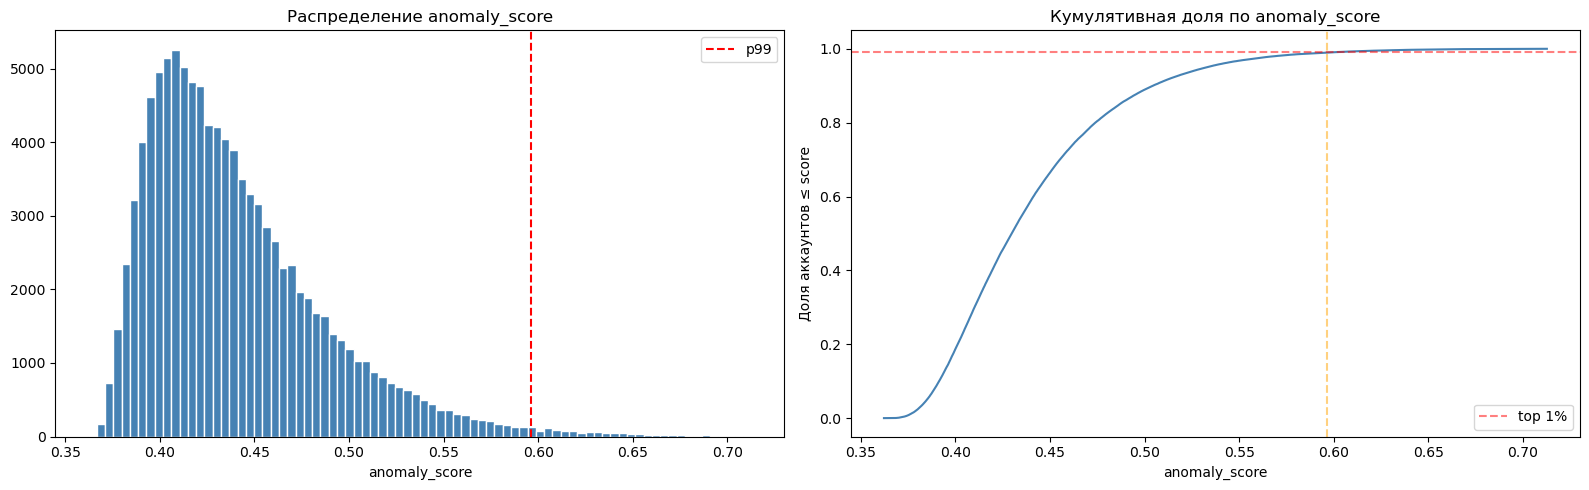

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Гистограмма
axes[0].hist(viz_pdf["anomaly_score"], bins=80, color="steelblue", edgecolor="white")
axes[0].axvline(viz_pdf["anomaly_score"].quantile(0.99), color="red", linestyle="--", label="p99")
axes[0].set_title("Распределение anomaly_score")
axes[0].set_xlabel("anomaly_score")
axes[0].legend()

# Кумулятивная доля
sorted_scores = np.sort(viz_pdf["anomaly_score"])
cumshare = np.arange(1, len(sorted_scores) + 1) / len(sorted_scores)
axes[1].plot(sorted_scores, cumshare, color="steelblue")
axes[1].axhline(0.99, color="red", linestyle="--", alpha=0.5, label="top 1%")
axes[1].axvline(np.percentile(sorted_scores, 99), color="orange", linestyle="--", alpha=0.5)
axes[1].set_title("Кумулятивная доля по anomaly_score")
axes[1].set_xlabel("anomaly_score")
axes[1].set_ylabel("Доля аккаунтов ≤ score")
axes[1].legend()

plt.tight_layout()
plt.show()

### Многомерный профиль: кандидаты против остальных (радар)

Сравниваем средние значения пяти ключевых метрик у `strong_candidate` и у остальных аккаунтов. Признак `avg_exc_gls` инвертирован (`−exc_gls`), чтобы «больше = лучше» на всех осях: низкая доля непотраченного золота означает эффективные покупки.

Значения нормированы в [0, 1] по минимуму и максимуму среди двух групп — радар показывает **относительный контраст**, а не абсолютные величины.

**Выводы:**
* **Кандидаты превосходят массу одновременно по всем пяти измерениям**, а не по одному показателю. Красный контур охватывает серый практически полностью.
* `avg_exc_dmg`: превышение урона над эталоном героя почти на два стандартных отклонения.
* `q25_exc_dmg` у кандидатов положительный и высокий: даже в худших 25% матчей они выше нормы. У остальных квартиль близок к нулю или отрицательный. Это подтверждает работу фильтра устойчивости.
* `avg_exc_den`: механическое превосходство в добивании крипов, признак, который трудно имитировать случайностью.
* `−avg_exc_gls` положителен у кандидатов: золото тратится эффективнее эталона. У остальных признак близок к нулю или отрицателен.
* **Ключевой вывод для защиты:** смурф-профиль — это не «высокая стата», а согласованное отклонение по нескольким независимым аспектам игры (урон, стабильность, механика, доминирование, эффективность ресурсов). Отбор по одному порогу GPM или KDA дал бы неприемлемый уровень ложных срабатываний, поскольку не проверяет согласованность профиля.

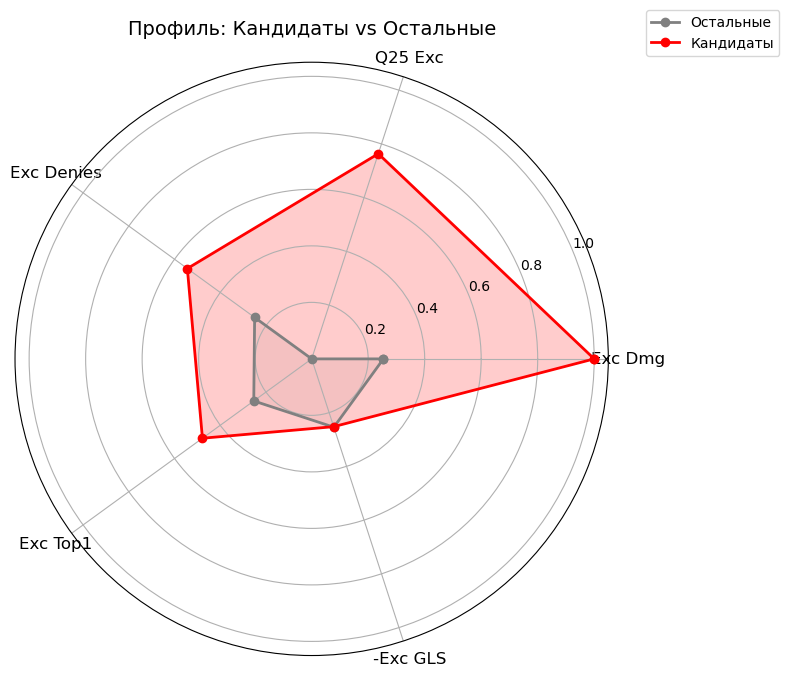

26/11/14 11:45:04 WARN JavaUtils: Attempt to delete using native Unix OS command failed for path = /tmp/spark-922295fc-0346-4e6c-92dc-c8ef236b7c00/pyspark-7f62a54f-d009-4c3f-a894-67c1ee489108. Falling back to Java IO way
java.io.IOException: Failed to delete: /tmp/spark-922295fc-0346-4e6c-92dc-c8ef236b7c00/pyspark-7f62a54f-d009-4c3f-a894-67c1ee489108
	at org.apache.spark.network.util.JavaUtils.deleteRecursivelyUsingUnixNative(JavaUtils.java:352)
	at org.apache.spark.network.util.JavaUtils.deleteRecursively(JavaUtils.java:269)
	at org.apache.spark.network.util.JavaUtils.deleteRecursively(JavaUtils.java:248)
	at org.apache.spark.util.SparkFileUtils.deleteRecursively(SparkFileUtils.scala:158)
	at org.apache.spark.util.SparkFileUtils.deleteRecursively$(SparkFileUtils.scala:157)
	at org.apache.spark.util.Utils$.deleteRecursively(Utils.scala:1062)
	at org.apache.spark.util.ShutdownHookManager$.$anonfun$new$4(ShutdownHookManager.scala:70)
	at org.apache.spark.util.ShutdownHookManager$.$anonfu

In [21]:
from math import pi
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Полные имена колонок из viz_pdf + вычисляемое поле
metrics_raw = ["avg_exc_dmg", "q25_exc_dmg", "avg_exc_den", "avg_exc_top1"]
labels = ["Exc Dmg", "Q25 Exc", "Exc Denies", "Exc Top1", "-Exc GLS"]

top = viz_pdf[viz_pdf["strong_candidate"] == 1][metrics_raw].copy()
other = viz_pdf[viz_pdf["strong_candidate"] == 0][metrics_raw].copy()

# Вычисляем -exc_gls отдельно (в viz_pdf колонка avg_exc_gls)
top["neg_exc_gls"] = -viz_pdf[viz_pdf["strong_candidate"] == 1]["avg_exc_gls"]
other["neg_exc_gls"] = -viz_pdf[viz_pdf["strong_candidate"] == 0]["avg_exc_gls"]

metrics = metrics_raw + ["neg_exc_gls"]

# Средние значения
top_mean = top[metrics].mean()
other_mean = other[metrics].mean()

# Нормировка в [0, 1] для радара
all_vals = pd.concat([top_mean, other_mean])
mins, maxs = all_vals.min(), all_vals.max()

if maxs - mins < 1e-9:
    print("Все значения одинаковы, радар не строится")
else:
    top_norm = (top_mean - mins) / (maxs - mins)
    other_norm = (other_mean - mins) / (maxs - mins)

    angles = [n / float(len(metrics)) * 2 * pi for n in range(len(metrics))]
    angles += angles[:1]
    top_vals = top_norm.tolist() + [top_norm.tolist()[0]]
    other_vals = other_norm.tolist() + [other_norm.tolist()[0]]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    ax.plot(angles, other_vals, 'o-', linewidth=2, label="Остальные", color="grey")
    ax.fill(angles, other_vals, alpha=0.1, color="grey")
    ax.plot(angles, top_vals, 'o-', linewidth=2, label="Кандидаты", color="red")
    ax.fill(angles, top_vals, alpha=0.2, color="red")
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_title("Профиль: Кандидаты vs Остальные", fontsize=14, pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
    plt.tight_layout()
    plt.show()